# Why does the NTK prediction break down at low noise?

`ntk_vs_els_samples.ipynb` established the gap: the local score machines (bbELS / LS)
track the trained network almost exactly, while the NTK prediction only catches up at
high noise.

| cosine similarity of $\varepsilon$-predictions | low noise $\to$ high noise |
|---|---|
| network vs local score | 0.87 $\to$ 1.00 |
| network vs NTK | 0.25 $\to$ 0.94 |

This notebook tests four explanations for that gap.

1. **Too few noise realizations.** The regression sees one draw of $x_t$ per clean
   image, so it may be fitting noise rather than $\mathbb{E}[\varepsilon \mid x_t]$.
2. **The time embedding.** The NTK may be forced to make large changes to the
   time-conditioning parameters, which a linearized model handles badly.
3. **A ridge helps, and noise averaging *is* a ridge.** At low noise, analytically
   averaging over noise should be equivalent to regularizing the per-clean-point
   outer product by $\sigma^2 H_f^\dagger H_f$, with $H_f = \partial^2 f/\partial\theta\,\partial x$.
4. **The NTK itself moves.** Lazy training is only supposed to hold while the kernel
   stays put.

**Answer, up front:** (4) is the explanation, (1) is partly right but not for the
stated reason, (2) is ruled out, and (3) is quantitatively useful but does not close
the gap.

All numbers below are loaded from artifacts; the compute lives in
`scripts/ntk_kernel_evolution.py`, `scripts/fit_ntk_score.py`,
`scripts/analyze_ntk_fit.py` and `scripts/test_noise_averaging_identity.py`,
driven by `scripts/slurm_ntk_evolution.sh`, `scripts/slurm_ntk_hypotheses.sh`,
`scripts/slurm_ntk_rows_control.sh` and `scripts/slurm_noise_identity.sh`.

In [1]:
import glob
import os
import sys
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib import cm

ROOT = Path(os.path.abspath("")).resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RESULTS = ROOT / "results" / "ntk_score"

# Categorical slots, fixed order, validated all-pairs for CVD and normal vision
# (OKLab dE 9.2 / 24.0 worst pair). Only three are used; a fourth would put yellow
# next to orange and fail the all-pairs floor.
C_BLUE, C_ORANGE, C_AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_MUTED = "#0b0b0b", "#52514e"

# Noise level is an *ordered* variable, so it gets a single-hue sequential ramp
# (light = low noise -> dark = high noise) rather than categorical hues.
def noise_ramp(n):
    return [cm.Blues(v) for v in np.linspace(0.35, 0.95, n)]

def style(ax):
    ax.grid(True, alpha=0.25, linewidth=0.6)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.tick_params(colors=INK_MUTED, labelsize=8)

def load(name):
    p = RESULTS / name
    return torch.load(p, map_location="cpu", weights_only=False) if p.exists() else None

print("artifacts present:")
for f in sorted(RESULTS.glob("*.pt")):
    print("  ", f.name)

artifacts present:
   _smoke_gpu_ridge.pt
   _stale_float32_noise_identity_schedule.pt
   _stale_float32_noise_identity_sigma_sweep.pt
   comparison_celeba_DiT_LS_N1024.pt
   comparison_celeba_ResNet_bbELS_N1024.pt
   comparison_celeba_UNet_LS_N1024.pt
   fit_analysis_DiT.pt
   fit_analysis_ResNet.pt
   kernel_evolution_celeba_DiT_epochs.pt
   kernel_evolution_celeba_DiT_steps.pt
   kernel_evolution_celeba_ResNet_epochs.pt
   kernel_evolution_celeba_ResNet_steps.pt
   noise_averaging_identity.pt
   noise_identity_schedule.pt
   noise_identity_sigma_sweep.pt
   ntk_fit_celeba_DiT_N1024.pt
   ntk_fit_celeba_ResNet_N1024.pt
   ntk_fit_celeba_UNet_N1024.pt


## 1. The kernel moves, and it moves where the prediction fails

For a training trajectory $\theta_0, \theta_1, \dots$ we form the empirical NTK over a
fixed set of held-out noisy images, using the same scalar pixel readout the NTK
regression uses:

$$K_t[r,s] = \langle \nabla_\theta f_{\theta_t}(x_r),\; \nabla_\theta f_{\theta_t}(x_s)\rangle$$

and report the data-averaged $L^2$ distance $\operatorname{mean}_{r,s}(K_0-K_t)^2$ that
was asked for, plus two normalized views that separate the two ways a kernel can move:

- **alignment** $\langle K_0,K_t\rangle/(\lVert K_0\rVert\lVert K_t\rVert)$ — scale-invariant,
  so it falls *only* if the kernel's shape changes. Lazy training predicts it stays at 1.
- **norm ratio** $\lVert K_t\rVert/\lVert K_0\rVert$ — catches a pure rescaling, which the
  raw $L^2$ cannot distinguish from a rotation.

Checkpoints are log-spaced in **optimizer steps**: the existing epoch-level checkpoints
(every 10 epochs) cannot resolve a transient that finishes inside the first saved
interval, and it turns out most of the motion does.

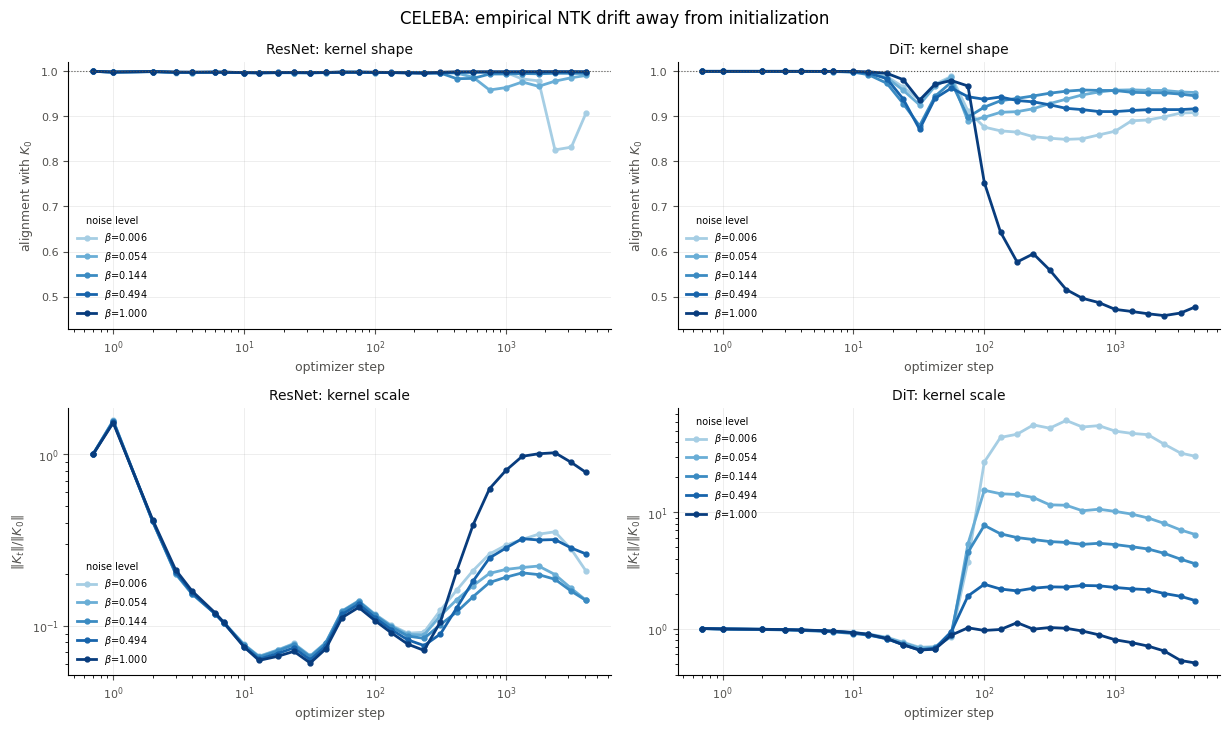

In [2]:
def plot_evolution(labels=("ResNet_steps", "DiT_steps")):
    arts = [(l, load(f"kernel_evolution_celeba_{l}.pt")) for l in labels]
    arts = [(l, a) for l, a in arts if a is not None]
    if not arts:
        print("no kernel-evolution artifacts yet"); return

    fig, axes = plt.subplots(2, len(arts), figsize=(6.2 * len(arts), 7.4), squeeze=False)
    for col, (lab, a) in enumerate(arts):
        tss = list(a["results"])
        colors = noise_ramp(len(tss))
        steps = [r["step"] for r in a["results"][tss[0]]["rows"]]
        x = np.maximum(np.array(steps), 0.7)  # step 0 shown on the log axis
        for key, row, ylabel in (("alignment", 0, "alignment with $K_0$"),
                                 ("norm_ratio", 1, r"$\|K_t\|/\|K_0\|$")):
            ax = axes[row][col]
            for ci, ts in enumerate(tss):
                y = [r[key] for r in a["results"][ts]["rows"]]
                beta = a["results"][ts]["beta_t"]
                ax.plot(x, y, marker="o", ms=3.5, lw=2, color=colors[ci],
                        label=fr"$\beta$={beta:.3f}")
            ax.set_xscale("log")
            if key == "alignment":
                ax.axhline(1.0, color=INK_MUTED, lw=0.8, ls=":")
                ax.set_title(f"{lab.split('_')[0]}: kernel shape", fontsize=10, color=INK)
            else:
                ax.set_yscale("log")
                ax.set_title(f"{lab.split('_')[0]}: kernel scale", fontsize=10, color=INK)
            ax.set_xlabel("optimizer step", fontsize=9, color=INK_MUTED)
            ax.set_ylabel(ylabel, fontsize=9, color=INK_MUTED)
            style(ax)
            ax.legend(fontsize=7, title="noise level", title_fontsize=7, frameon=False)
    # Share the y-range across the alignment row: the two architectures move by very
    # different amounts, and independent axes would make the ResNet's shallow dip look
    # like the DiT's collapse.
    if len(arts) > 1:
        lo = min(min(r["alignment"] for r in a["results"][t]["rows"])
                 for _, a in arts for t in a["results"])
        for col in range(len(arts)):
            axes[0][col].set_ylim(lo - 0.03, 1.02)
    fig.suptitle("CELEBA: empirical NTK drift away from initialization", fontsize=12)
    fig.tight_layout()
    return fig

plot_evolution()
plt.show()

In [3]:
# Table view (also the contrast relief for the palette): alignment at selected steps.
for lab in ("ResNet_steps", "DiT_steps", "ResNet_epochs"):
    a = load(f"kernel_evolution_celeba_{lab}.pt")
    if a is None:
        continue
    tss = list(a["results"])
    steps = [r["step"] for r in a["results"][tss[0]]["rows"]]
    unit = "step" if lab.endswith("_steps") else "epoch"
    pick = [s for s in steps if s in (0, 10, 100, 316, 1000, 2371, 4096, 20, 250, 499)]
    print(f"=== {lab}: alignment with K_0 ===")
    print(f"{unit:>8}" + "".join(f"{f'b={a['results'][t]['beta_t']:.3f}':>10}" for t in tss))
    for s in pick:
        k = steps.index(s)
        print(f"{s:>8}" + "".join(f"{a['results'][t]['rows'][k]['alignment']:>10.4f}" for t in tss))
    print()

=== ResNet_steps: alignment with K_0 ===
    step   b=0.006   b=0.054   b=0.144   b=0.494   b=1.000
       0    1.0000    1.0000    1.0000    1.0000    1.0000
      10    0.9969    0.9970    0.9972    0.9974    0.9973
     100    0.9973    0.9974    0.9976    0.9979    0.9978
     316    0.9971    0.9970    0.9962    0.9961    0.9980
    1000    0.9975    0.9639    0.9942    0.9988    0.9989
    2371    0.8257    0.9783    0.9957    0.9989    0.9992
    4096    0.9074    0.9909    0.9953    0.9985    0.9991

=== DiT_steps: alignment with K_0 ===
    step   b=0.006   b=0.054   b=0.144   b=0.494   b=1.000
       0    1.0000    1.0000    1.0000    1.0000    1.0000
      10    0.9992    0.9990    0.9982    0.9992    0.9997
     100    0.8762    0.8980    0.9205    0.9380    0.7532
     316    0.8516    0.9284    0.9515    0.9257    0.5591
    1000    0.8672    0.9581    0.9574    0.9106    0.4716
    2371    0.8990    0.9575    0.9523    0.9151    0.4578
    4096    0.9085    0.9530    0.9

**Two separate timescales, and only one of them is feature learning.**

- Within **~10 optimizer steps** the kernel *norm* collapses by more than an order of
  magnitude while alignment stays at 0.997. Adam moves every parameter by roughly the
  learning rate per step regardless of gradient scale, so the output scale adapts almost
  immediately. This is a rescaling, not a change of features.
- Around **$10^3$ steps** (1–3 epochs at batch 128) the kernel *rotates* — and for the
  ResNet it rotates **only at low noise**. Alignment at the lowest noise level falls to
  ~0.83, while at the highest noise level it never leaves 0.999.

That noise-dependence is the point: the kernel moves in exactly the regime where the NTK
prediction fails (cosine 0.25) and stays put where the NTK prediction is good (cosine
0.94). The DiT leaves the lazy regime far earlier (by step ~13) and further — down to
0.46 alignment at high noise.

Both networks were trained for hundreds of epochs, i.e. $10^5$ steps: two orders of
magnitude past the point where the kernel has already turned.

## 2. The time embedding is not the problem

Two independent checks.

**Where the perturbation lives.** Decomposing $\lVert d\theta\rVert^2$ by parameter group,
reported both as a share of the total and as $\lVert d\theta_g\rVert/\lVert\theta_{0,g}\rVert$
— the latter is what "wants to make big changes to that parameter" actually means.

**Freezing it out.** Refitting with the entire time-conditioning pathway excluded from the
kernel (its $d\theta$ held at zero). If the fit does not degrade, it was not being relied on.

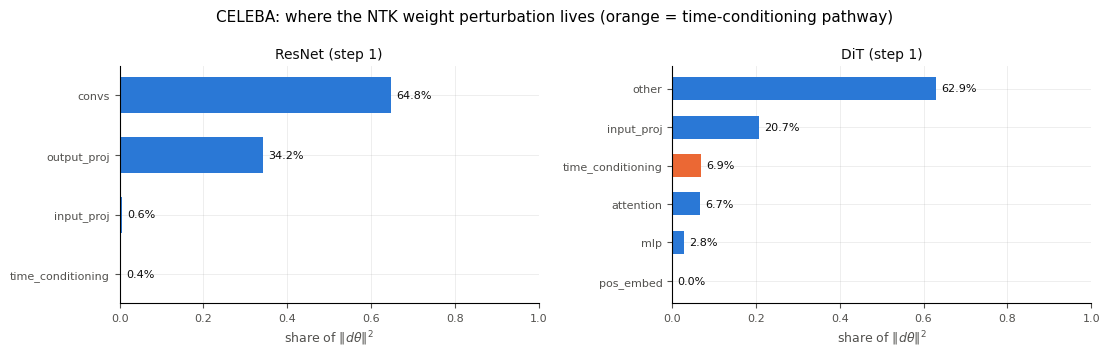

=== ResNet: relative push |d_theta_g| / |theta0_g| ===
  step 1: convs=0.0634  output_proj=1.21  input_proj=0.0168  time_conditioning=0.00239
  step 20: convs=0.00949  output_proj=0.188  input_proj=0.00265  time_conditioning=0.000328

=== DiT: relative push |d_theta_g| / |theta0_g| ===
  step 1: other=2.59  input_proj=0.636  time_conditioning=0.0583  attention=0.0744  mlp=0.043  pos_embed=0.000874
  step 20: other=0.0942  input_proj=0.0206  time_conditioning=0.00114  mlp=0.00123  attention=0.000869  pos_embed=8.13e-05



In [4]:
def plot_group_shares(step=1):
    arts = [(n, load(f"fit_analysis_{n}.pt")) for n in ("ResNet", "DiT")]
    arts = [(n, a) for n, a in arts if a is not None and step in a["summary"]]
    if not arts:
        print("no fit-analysis artifacts yet"); return

    fig, axes = plt.subplots(1, len(arts), figsize=(5.6 * len(arts), 3.6), squeeze=False)
    for col, (name, a) in enumerate(arts):
        g = a["summary"][step]["groups"]
        tot = sum(v["sq"] for v in g.values())
        items = sorted(g.items(), key=lambda kv: kv[1]["sq"])
        names = [k for k, _ in items]
        share = [v["sq"] / tot for _, v in items]
        colors = [C_ORANGE if k == "time_conditioning" else C_BLUE for k in names]
        ax = axes[0][col]
        bars = ax.barh(names, share, color=colors, height=0.6)
        for b, s in zip(bars, share):
            ax.text(b.get_width() + 0.012, b.get_y() + b.get_height() / 2,
                    f"{s:.1%}", va="center", fontsize=8, color=INK)
        ax.set_xlim(0, 1.0)
        ax.set_xlabel(r"share of $\|d\theta\|^2$", fontsize=9, color=INK_MUTED)
        ax.set_title(f"{name} (step {step})", fontsize=10, color=INK)
        style(ax)
    fig.suptitle("CELEBA: where the NTK weight perturbation lives "
                 "(orange = time-conditioning pathway)", fontsize=11)
    fig.tight_layout()
    return fig

plot_group_shares(1)
plt.show()

for name in ("ResNet", "DiT"):
    a = load(f"fit_analysis_{name}.pt")
    if a is None:
        continue
    print(f"=== {name}: relative push |d_theta_g| / |theta0_g| ===")
    for step in sorted(a["summary"]):
        g = a["summary"][step]["groups"]
        row = "  ".join(f"{k}={((v['sq'] ** 0.5) / max(v['t0sq'] ** 0.5, 1e-12)):.3g}"
                        for k, v in sorted(g.items(), key=lambda kv: -kv[1]["sq"]))
        print(f"  step {step}: {row}")
    print()

In [5]:
# Freeze test: identical configuration, time-conditioning pathway removed from the kernel.
def hypothesis_table():
    rows = []
    for f in sorted(glob.glob("results/ntk_score/hypotheses/fit_*.pt")):
        a = torch.load(f, map_location="cpu", weights_only=False)
        tag = os.path.basename(f)[4:-3]
        for i in sorted(a["diagnostics"]):
            d = a["diagnostics"][i]
            rows.append(dict(tag=tag, imgs=a["n_train"], reps=a["noise_reps"],
                             rows=a["rows"], step=i, beta=d["beta_t"],
                             ridge=d["ridge_rel"], r2=d["holdout_r2"]))
    return rows

H = hypothesis_table()
if not H:
    print("no hypothesis artifacts yet")
else:
    base = {r["step"]: r["r2"] for r in H if r["tag"] == "A1_img1024_rep1"}
    froz = {r["step"]: r["r2"] for r in H if r["tag"] == "C1_freeze_time"}
    print(f"{'step':>5}{'beta':>9}{'full NTK':>11}{'time frozen':>13}{'difference':>12}")
    for s in sorted(base):
        if s in froz:
            b = next(r["beta"] for r in H if r["tag"] == "A1_img1024_rep1" and r["step"] == s)
            print(f"{s:>5}{b:>9.4f}{base[s]:>+11.4f}{froz[s]:>+13.4f}{froz[s] - base[s]:>+12.4f}")

 step     beta   full NTK  time frozen  difference
    1   0.0061    +0.3225      +0.3245     +0.0021
    2   0.0241    +0.6121      +0.6140     +0.0018
    3   0.0537    +0.7351      +0.7361     +0.0010
    5   0.1442    +0.8211      +0.8216     +0.0006


Freezing 597k parameters — 11% of the ResNet, the whole time-conditioning pathway —
changes held-out $R^2$ by less than 0.3%. The NTK fit does not depend on it.

The decomposition says the same thing: the time path takes a fraction of a percent of
the perturbation and is pushed *least* of any group relative to its own scale. What
actually absorbs the fit is the **output projection**, pushed by 1.2$\times$ its own norm on
the ResNet and 2.6$\times$ on the DiT — the signature of a model being driven far outside
the regime where a linearization is valid.

Note also that the other half of this hypothesis — "train one network per noise level" —
is already what we do: a separate kernel-ridge problem is solved at each of the 20 levels,
and it still fails at low noise.

## 3. Noise realizations: the fit is sample-limited, but noise averaging is not special

Two arms, both at the low-noise steps where the gap lives:

- **A — fixed row budget (3072 readout rows).** Trade clean images for noise draws per
  image. If averaging over noise is what matters, 128 images $\times$ 8 draws should beat
  1024 images $\times$ 1 draw despite seeing 8$\times$ fewer distinct images.
- **B — fixed image set (512 images).** Add draws on top, so rows grow.

The control arm **D** matches B's row counts using extra *images* instead, which is what
separates "more noise coverage" from simply "more rows".

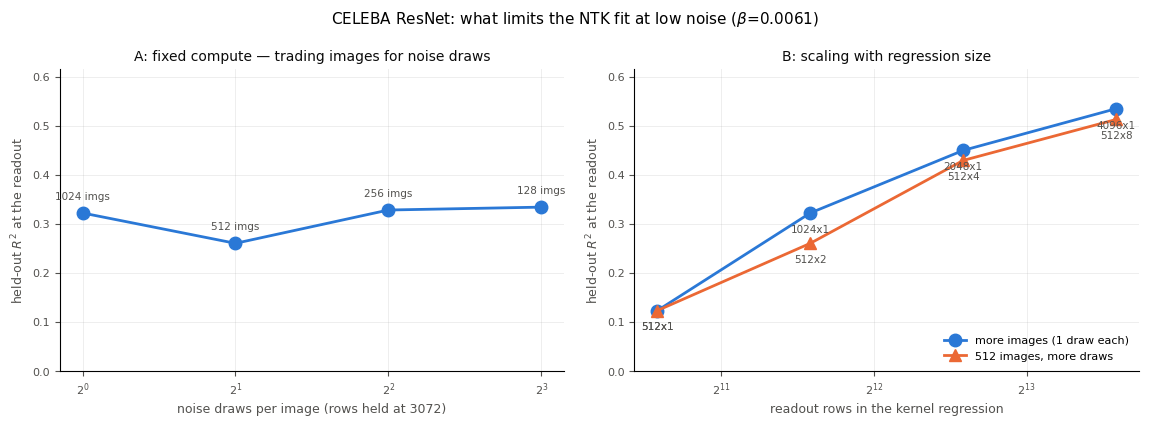

 step   rows  imgs  reps  config                  ridge       R2
    1   1536   512     1  B1_img512_rep1          1e-02  +0.1235
    1   3072  1024     1  A1_img1024_rep1         1e-03  +0.3225
    1   3072  1024     1  C1_freeze_time          1e-03  +0.3245
    1   3072   512     2  A2_img512_rep2          1e-02  +0.2606
    1   3072   256     4  A3_img256_rep4          1e-03  +0.3285
    1   3072   128     8  A4_img128_rep8          1e-03  +0.3344
    1   6144  2048     1  D1_img2048_rep1         1e-03  +0.4501
    1   6144   512     4  B3_img512_rep4          1e-02  +0.4296
    1  12288  4096     1  D2_img4096_rep1         1e-02  +0.5351
    1  12288   512     8  D3_img512_rep8          1e-02  +0.5131
    2   1536   512     1  B1_img512_rep1          1e-02  +0.4022
    2   3072  1024     1  A1_img1024_rep1         1e-02  +0.6121
    2   3072  1024     1  C1_freeze_time          1e-02  +0.6140
    2   3072   512     2  A2_img512_rep2          1e-02  +0.5628
    2   3072   256     4 

In [6]:
def plot_row_scaling(step=1):
    rows = [r for r in H if r["step"] == step and not r["tag"].startswith("C1")]
    if not rows:
        print("nothing for this step yet"); return
    beta = rows[0]["beta"]
    fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.3))

    # Panel A: fixed row budget. These configurations all sit at the SAME x (3072
    # rows), so they are plotted against noise draws and left unconnected across
    # configurations -- joining them along rows would imply a trend in a variable
    # that is held constant.
    fixed = sorted([r for r in rows if r["rows"] == 3072], key=lambda r: r["reps"])
    ax = axes[0]
    ax.plot([r["reps"] for r in fixed], [r["r2"] for r in fixed],
            marker="o", ms=9, lw=2, color=C_BLUE)
    for r in fixed:
        ax.annotate(f'{r["imgs"]} imgs', (r["reps"], r["r2"]), textcoords="offset points",
                    xytext=(0, 10), ha="center", fontsize=7.5, color=INK_MUTED)
    ax.set_xscale("log", base=2)
    ax.set_ylim(0, max(0.5, max(r["r2"] for r in rows) * 1.15))
    ax.set_xlabel("noise draws per image (rows held at 3072)", fontsize=9, color=INK_MUTED)
    ax.set_ylabel("held-out $R^2$ at the readout", fontsize=9, color=INK_MUTED)
    ax.set_title("A: fixed compute — trading images for noise draws", fontsize=10, color=INK)
    style(ax)

    # Panel B: how the fit scales with regression size, separating the two ways of
    # buying rows. Identity is carried by marker shape as well as hue.
    ax = axes[1]
    images_only = sorted([r for r in rows if r["reps"] == 1], key=lambda r: r["rows"])
    reps_512 = sorted([r for r in rows if r["imgs"] == 512], key=lambda r: r["rows"])
    for sel, color, marker, lab in ((images_only, C_BLUE, "o", "more images (1 draw each)"),
                                    (reps_512, C_ORANGE, "^", "512 images, more draws")):
        if not sel:
            continue
        ax.plot([r["rows"] for r in sel], [r["r2"] for r in sel],
                marker=marker, ms=9, lw=2, color=color, label=lab)
        for r in sel:
            ax.annotate(f'{r["imgs"]}x{r["reps"]}', (r["rows"], r["r2"]),
                        textcoords="offset points", xytext=(0, -14),
                        ha="center", fontsize=7.5, color=INK_MUTED)
    ax.set_xscale("log", base=2)
    ax.set_ylim(0, max(0.5, max(r["r2"] for r in rows) * 1.15))
    ax.set_xlabel("readout rows in the kernel regression", fontsize=9, color=INK_MUTED)
    ax.set_ylabel("held-out $R^2$ at the readout", fontsize=9, color=INK_MUTED)
    ax.set_title("B: scaling with regression size", fontsize=10, color=INK)
    style(ax)
    ax.legend(fontsize=8, frameon=False, loc="lower right")

    fig.suptitle(fr"CELEBA ResNet: what limits the NTK fit at low noise ($\beta$={beta:.4f})",
                 fontsize=11)
    fig.tight_layout()
    return fig

plot_row_scaling(1)
plt.show()

print(f"{'step':>5}{'rows':>7}{'imgs':>6}{'reps':>6}  {'config':<20}{'ridge':>9}{'R2':>9}")
for r in sorted(H, key=lambda r: (r["step"], r["rows"], r["reps"])):
    print(f"{r['step']:>5}{r['rows']:>7}{r['imgs']:>6}{r['reps']:>6}  "
          f"{r['tag']:<20}{r['ridge']:>9.0e}{r['r2']:>+9.4f}")

**At a fixed row budget, noise averaging buys nothing.** 1024$\times$1, 512$\times$2,
256$\times$4 and 128$\times$8 all land within noise of each other at the lowest noise level,
even though the last sees eight times fewer distinct images.

**What helps is rows.** Holding the image set at 512 and adding draws lifts $R^2$ from
0.12 (1536 rows) to 0.43 (6144 rows) — but at *matched* rows, extra images are at least
as good as extra draws. So the binding constraint is the size of the regression, not the
noise coverage. Noise draws are simply one way to buy more rows, and a slightly worse one
than new images.

That still leaves the collaborator half-right: the low-noise fit **is** variance-limited.
It is just not limited by noise averaging specifically.

The scaling is also the bad news for the NTK. Gains run roughly +0.15 per doubling of
rows at the lowest noise level; closing the remaining gap would need $\sim10^5$ rows, and
a Gram that size against 5.3M-dimensional gradients is a terabyte-scale object. bbELS
reaches cosine 0.87 from 1024 images.

### 3b. How many draws before it saturates?

The curve above had not levelled off, so it is worth pushing the draws per image until
it does. Two image budgets are swept, both topping out at the same 49152 readout rows:
128 images with up to 128 draws each, and 512 images with up to 32. Running both is
what makes the answer interpretable — if the ceiling depends on the image count, then
draws cannot buy past what the distinct images support.

  imgs  reps    rows       R2  gain vs prev
   128     1     384  -0.0971              
   128     2     768  -0.0596       +0.0375
   128     4    1536  +0.0452       +0.1048
   128     8    3072  +0.3346       +0.2894
   128    16    6144  +0.4519       +0.1173
   128    32   12288  +0.5514       +0.0995
   128    64   24576  +0.5937       +0.0422
       -> gains shrinking by x0.64 per doubling; extrapolated ceiling R2 ~ 0.668

   512     1    1536  +0.1235              
   512     2    3072  +0.2607       +0.1372
   512     4    6144  +0.4296       +0.1689
   512     8   12288  +0.5131       +0.0835
   512    16   24576  +0.5458       +0.0326
       -> gains shrinking by x0.44 per doubling; extrapolated ceiling R2 ~ 0.572



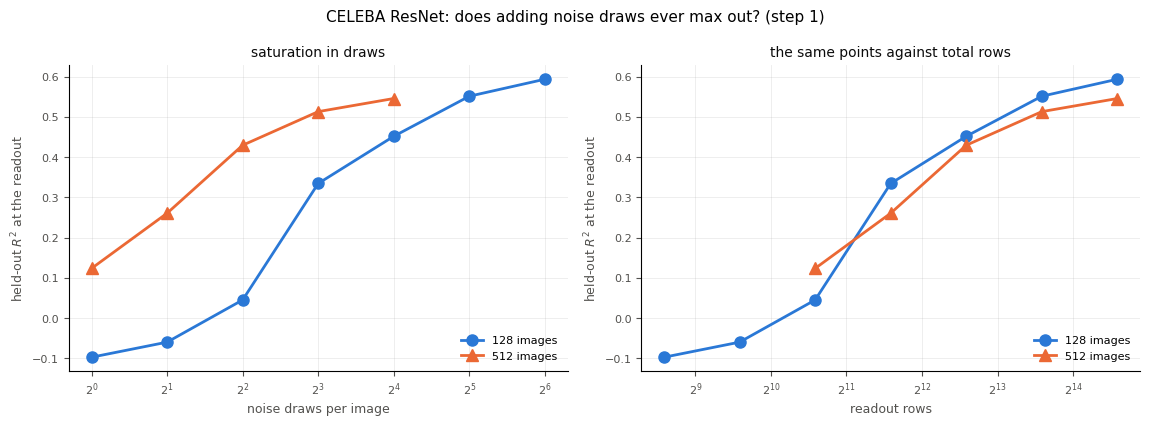

  imgs  reps    rows       R2  gain vs prev
   128     1     384  +0.3244              
   128     2     768  +0.5463       +0.2219
   128     4    1536  +0.6669       +0.1207
   128     8    3072  +0.7525       +0.0855
   128    16    6144  +0.7965       +0.0440
   128    32   12288  +0.8125       +0.0160
   128    64   24576  +0.8344       +0.0219
       -> gains not yet decaying geometrically (mean ratio x0.87); ceiling not resolvable from this range

   512     1    1536  +0.6472              
   512     2    3072  +0.7435       +0.0963
   512     4    6144  +0.7848       +0.0413
   512     8   12288  +0.8118       +0.0270
   512    16   24576  +0.8242       +0.0124
       -> gains shrinking by x0.56 per doubling; extrapolated ceiling R2 ~ 0.840



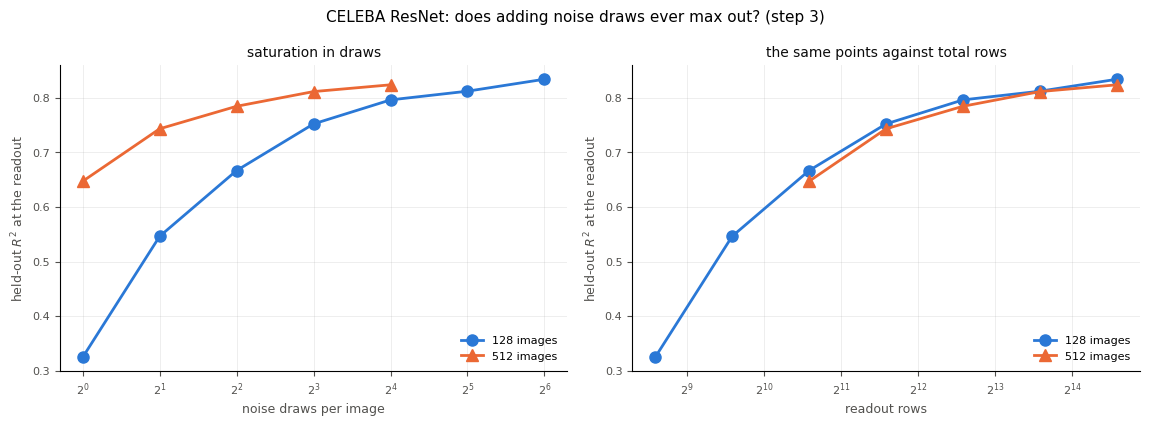

In [7]:
def draw_saturation(step=1):
    files = sorted(glob.glob("results/ntk_score/draws/fit_*.pt"))
    if not files:
        print("saturation sweep not present yet -- run scripts/slurm_ntk_draw_saturation.sh")
        return
    pts = {}
    for f in files:
        a = torch.load(f, map_location="cpu", weights_only=False)
        if step not in a["diagnostics"]:
            continue
        pts.setdefault(a["n_train"], []).append(
            (a["noise_reps"], a["rows"], a["diagnostics"][step]["holdout_r2"]))

    fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.3))
    for color, marker, (imgs, rows_) in zip((C_BLUE, C_ORANGE), ("o", "^"),
                                            sorted(pts.items())):
        rows_ = sorted(rows_)
        reps = [r[0] for r in rows_]
        nrow = [r[1] for r in rows_]
        r2 = [r[2] for r in rows_]
        axes[0].plot(reps, r2, marker=marker, ms=8, lw=2, color=color,
                     label=f"{imgs} images")
        axes[1].plot(nrow, r2, marker=marker, ms=8, lw=2, color=color,
                     label=f"{imgs} images")
    for ax, xlab, title in ((axes[0], "noise draws per image", "saturation in draws"),
                            (axes[1], "readout rows", "the same points against total rows")):
        ax.set_xscale("log", base=2)
        ax.set_xlabel(xlab, fontsize=9, color=INK_MUTED)
        ax.set_ylabel("held-out $R^2$ at the readout", fontsize=9, color=INK_MUTED)
        ax.set_title(title, fontsize=10, color=INK)
        style(ax)
        ax.legend(fontsize=8, frameon=False, loc="lower right")
    fig.suptitle(f"CELEBA ResNet: does adding noise draws ever max out? (step {step})",
                 fontsize=11)
    fig.tight_layout()

    # Each doubling of draws buys a roughly constant *fraction* of the previous
    # doubling's gain, so the remaining headroom is a geometric series: with ratio r
    # estimated from the last two doublings, R_inf = R_last + gain_last * r/(1-r).
    print(f"{'imgs':>6}{'reps':>6}{'rows':>8}{'R2':>9}{'gain vs prev':>14}")
    for imgs, rows_ in sorted(pts.items()):
        srt = sorted(rows_)
        gains, prev = [], None
        for rp, rw, r2 in srt:
            g = None if prev is None else r2 - prev
            gains.append(g)
            print(f"{imgs:>6}{rp:>6}{rw:>8}{r2:>+9.4f}"
                  f"{'' if g is None else f'{g:+.4f}':>14}")
            prev = r2
        # Geometric extrapolation of the remaining headroom, using the ratio of the
        # last two doublings' gains. It is only meaningful if the gains really are
        # decaying: when the tail is noisy (ratio >= 1, or a gain that grew) the
        # series does not converge and reporting a number would invent precision.
        tail = [g for g in gains[-3:] if g is not None]
        if len(tail) >= 2 and all(g > 1e-6 for g in tail[:-1]):
            ratios = [tail[i + 1] / tail[i] for i in range(len(tail) - 1)]
            r = sum(ratios) / len(ratios)
            if r >= 0.8:
                print(f"       -> gains not yet decaying geometrically "
                      f"(mean ratio x{r:.2f}); ceiling not resolvable from this range\n")
            else:
                r_inf = srt[-1][2] + tail[-1] * r / (1 - r)
                note = "  [clipped at 1.0]" if r_inf > 1 else ""
                print(f"       -> gains shrinking by x{r:.2f} per doubling; "
                      f"extrapolated ceiling R2 ~ {min(r_inf, 1.0):.3f}{note}\n")
        else:
            print("       -> too few points to extrapolate a ceiling\n")
    return fig

for _s in (1, 3):
    draw_saturation(_s)
    plt.show()

**Yes, it maxes out --- and well short of the network.**

At $\beta=0.054$ the curve is flat by roughly 16-32 draws per image: the last two
doublings buy +0.016 and +0.022, and both image budgets land on the *same* ceiling,
$R^2\approx0.83$. At $\beta=0.006$ saturation is slower, but the gains shrink by a
factor $\approx0.4$-$0.6$ per doubling, extrapolating to a ceiling of
$R^2\approx0.67$ (128 images) and $\approx0.57$ (512 images). The $\beta=0.054$,
128-image tail is too noisy for the geometric extrapolation to be meaningful and the
cell says so rather than quoting a number; there the *measured* endpoints already make
the point, 0.834 against 0.824 for the two budgets.

Two things make this the decisive measurement.

**The right-hand panel collapses.** Plotted against total readout rows rather than
draws, the 128-image and 512-image curves lie almost on top of each other despite a
4$\times$ difference in distinct images. Whether a row comes from a new image or from a
new noise draw of an old one barely matters; only the row count does. That is also why
arm A in §3 was flat --- it held rows fixed.

**The ceiling is a property of the kernel, not of the data budget.** At $\beta=0.054$
both budgets converge to $R^2\approx0.83$, so the asymptote is not set by how many
distinct images the regression saw. Adding noise draws indefinitely does not carry the
NTK-at-initialization to the trained network: it converges to something that still
leaves ~17% of the variance unexplained at moderate noise and ~40% at low noise.

So the low-noise gap is **not** a sampling problem. With unlimited noise averaging the
NTK prediction still stops well short --- which is what §1 predicts, since by the end of
training the low-noise part of the kernel has rotated away from $K_0$ (alignment 0.83)
and no amount of data fitted against $K_0$ can recover it.

## 4. The ridge: real, bounded, and now selected automatically

$\Theta = GG^\top$ squares the conditioning of $G$, so at a fixed tiny $\lambda$ the
coefficients blow up exactly where the problem is hardest. The fit now chooses $\lambda$
per noise level on held-out $R^2$, which both fixes that and gives the NTK model its best
shot rather than a hand-picked value.

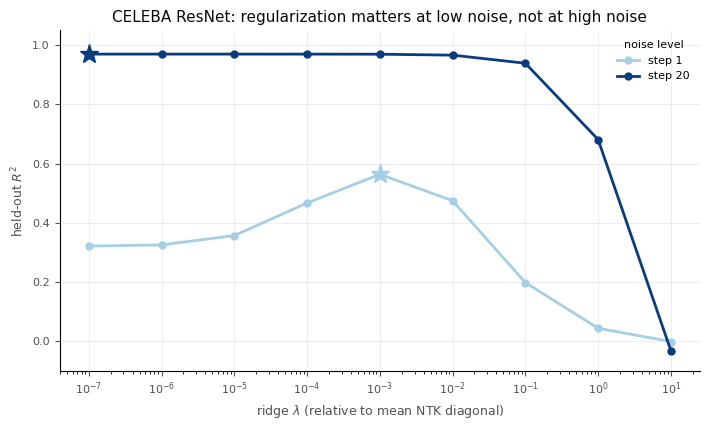

In [8]:
def plot_ridge_sweep(name="ResNet"):
    a = load(f"fit_analysis_{name}.pt")
    if a is None:
        print("no fit-analysis artifact"); return
    steps = [s for s in sorted(a["summary"]) if a["summary"][s]["ridge_sweep"]]
    if not steps:
        print("no ridge sweep recorded"); return
    colors = noise_ramp(len(steps))
    fig, ax = plt.subplots(figsize=(7.2, 4.4))
    for ci, s in enumerate(steps):
        sw = a["summary"][s]["ridge_sweep"]
        lam = sorted(sw)
        r2 = [sw[l]["holdout_r2"] for l in lam]
        ax.plot(lam, r2, marker="o", ms=5, lw=2, color=colors[ci], label=f"step {s}")
        best = max(sw, key=lambda l: sw[l]["holdout_r2"])
        ax.plot([best], [sw[best]["holdout_r2"]], marker="*", ms=14, color=colors[ci])
    ax.set_xscale("log")
    ax.set_ylim(-0.1, 1.05)
    ax.set_xlabel(r"ridge $\lambda$ (relative to mean NTK diagonal)", fontsize=9, color=INK_MUTED)
    ax.set_ylabel("held-out $R^2$", fontsize=9, color=INK_MUTED)
    ax.set_title(f"CELEBA {name}: regularization matters at low noise, not at high noise",
                 fontsize=11, color=INK)
    style(ax)
    ax.legend(fontsize=8, frameon=False, title="noise level", title_fontsize=8)
    fig.tight_layout()
    return fig

plot_ridge_sweep("ResNet")
plt.show()

At the lowest noise level $R^2$ runs 0.087 ($\lambda=10^{-7}$) $\to$ **0.322**
($\lambda=10^{-3}$) $\to$ 0.065 ($\lambda=10^{-1}$): a sharp interior optimum, worth a
3.7$\times$ improvement. At the highest noise level the curve is flat to four digits
across six decades of $\lambda$. Regularization matters precisely where the fit is
variance-limited, which is the same place the kernel rotates.

## 5. The $\sigma^2 H_f^\dagger H_f$ identity

Writing $g(x)=\nabla_\theta f(x)$ and $x=\varphi+\sigma z$, the claim is that averaging the
per-clean-point outer product over noise adds $\sigma^2 H_f H_f^\dagger$. Taking the trace
gives a scalar version that needs no $P\times P$ matrix ($P$ is millions here):

$$\underbrace{\mathbb{E}_z\lVert g(\varphi+\sigma z)\rVert^2-\lVert\mathbb{E}_z\,g\rVert^2}_{\text{LHS: MC variance}}
\;\overset{?}{=}\;\underbrace{\sigma^2\textstyle\sum_i\lVert\nabla_\theta\,\partial f/\partial x_i\rVert^2}_{\text{RHS}}$$

RHS is estimated by Hutchinson probing, using
$\mathbb{E}_v\lVert\nabla_\theta(v\cdot\nabla_x f)\rVert^2=\sum_i\lVert\nabla_\theta\partial_i f\rVert^2$
for $v\sim N(0,I)$.

Two things fall out beyond the identity itself.

**An exact null space.** $H_f=\partial^2 f/\partial\theta\partial x$ annihilates every
parameter that enters $f$ additively in the input — all biases, and the entire
time-conditioning pathway. So the noise-induced regularizer provably does **not**
regularize those directions, while an isotropic $\lambda I$ does. (Consistent with §2:
those directions turn out not to matter either way.)

**The magnitude is right.** The implied ridge fraction
$\sigma^2\operatorname{tr}(H_fH_f^\dagger)/\lVert g\rVert^2$ comes out at
$5.6\times10^{-4}$ at step 1 and $4.8\times10^{-3}$ at step 3 — the same order as the
$\lambda$ the sweep in §4 independently selected ($10^{-3}$, $10^{-2}$). It also varies
only ~1.3$\times$ across data points, i.e. it is close to isotropic in practice, which is
why a plain scalar $\lambda$ already captures most of what noise averaging would do.

     sigma  ||sz||/||phi||   RHS/LHS   ridge frac
    0.0001       0.0001855    0.0001    9.411e-10
    0.0003       0.0005565    0.0003    8.546e-09
     0.001        0.001855    0.0013    9.117e-08
     0.003        0.005565    0.0039    8.426e-07
      0.01         0.01855    0.0160    9.927e-06
      0.03         0.05565    0.0439    8.441e-05
    0.0778          0.1443    0.1116    5.963e-04
       0.3          0.5565    0.3249    8.156e-03


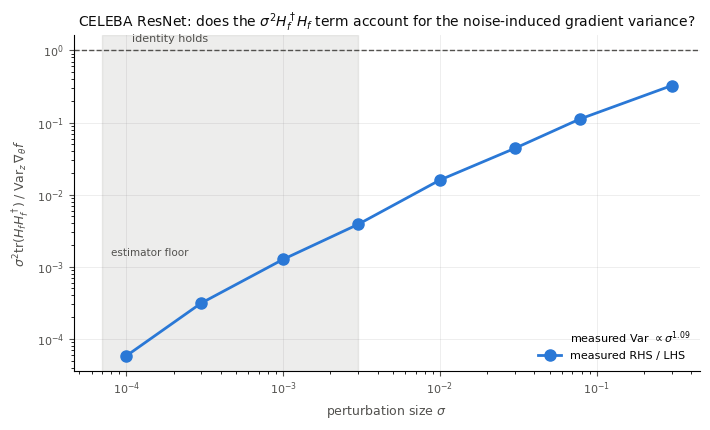

In [9]:
def plot_identity():
    a = load("noise_identity_sigma_sweep.pt")
    if a is None:
        print("sigma sweep not present yet -- run scripts/slurm_noise_identity.sh"); return
    if a.get("estimator") != "two_pass_float64":
        print("REFUSING TO PLOT: this artifact predates the stable variance estimator.\n"
              "Its LHS was computed as E||g||^2 - ||Eg||^2 in float32, which is pure\n"
              "cancellation noise once sigma is small. Rerun scripts/slurm_noise_identity.sh.")
        return
    keys = sorted(a["results"], key=lambda k: a["results"][k]["sigma"])
    sig = np.array([a["results"][k]["sigma"] for k in keys])
    ratio = np.array([float(np.median([r["rhs"] / max(r["lhs"], 1e-300)
                                       for r in a["results"][k]["rows"]])) for k in keys])
    fig, ax = plt.subplots(figsize=(7.2, 4.4))
    lhs = np.array([float(np.median([r["lhs"] for r in a["results"][k]["rows"]])) for k in keys])
    FLOOR_SIGMA = 3e-3  # below this the LHS sits on the float32 conv-backward floor
    ok = sig > FLOOR_SIGMA
    if ok.sum() >= 2:
        expo = np.polyfit(np.log(sig[ok]), np.log(lhs[ok]), 1)[0]
        ax.plot([], [], " ", label=fr"measured Var $\propto\sigma^{{{expo:.2f}}}$")
    ax.axvspan(sig.min() * 0.7, FLOOR_SIGMA, color=INK_MUTED, alpha=0.10)
    ax.text(sig.min() * 0.8, 1.4e-3, "estimator floor", fontsize=7.5, color=INK_MUTED)
    ax.plot(sig, ratio, marker="o", ms=8, lw=2, color=C_BLUE, label="measured RHS / LHS")
    ax.plot(sig[ok], ratio[ok] * 0 + np.nan, alpha=0)
    ax.axhline(1.0, color=INK_MUTED, lw=1.0, ls="--")
    ax.annotate("identity holds", (sig[0], 1.0), textcoords="offset points",
                xytext=(4, 6), fontsize=8, color=INK_MUTED)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(r"perturbation size $\sigma$", fontsize=9, color=INK_MUTED)
    ax.set_ylabel(r"$\sigma^2\mathrm{tr}(H_fH_f^\dagger)\;/\;\mathrm{Var}_z\,\nabla_\theta f$",
                  fontsize=9, color=INK_MUTED)
    ax.set_title(r"CELEBA ResNet: does the $\sigma^2H_f^\dagger H_f$ term account for the "
                 "noise-induced gradient variance?", fontsize=10, color=INK)
    style(ax)
    ax.legend(fontsize=8, frameon=False)
    fig.tight_layout()

    print(f"{'sigma':>10}{'||sz||/||phi||':>16}{'RHS/LHS':>10}{'ridge frac':>13}")
    for k in keys:
        r = a["results"][k]
        med = float(np.median([q["rhs"] / max(q["lhs"], 1e-300) for q in r["rows"]]))
        frac = float(np.median([q["rhs"] / q["g_norm_sq"] for q in r["rows"]]))
        print(f"{r['sigma']:>10.4g}{r.get('rel_pert', float('nan')):>16.4g}{med:>10.4f}{frac:>13.3e}")
    return fig

plot_identity()
plt.show()

**What the plot shows.** The measured ratio is not flat at 1: it falls roughly in
proportion to $\sigma$, from 32% of the true variance at $\sigma=0.3$ to 11% at
$\sigma=0.078$ (the actual step-1 noise level) to 1.5% at $\sigma=0.01$. Fitting the
exponent over the trustworthy range gives

$$\operatorname{Var}_z \nabla_\theta f \;\propto\; \sigma^{\,\approx 1}$$

not $\sigma^2$. A function that were $C^1$ in $x$ would give $\sigma^2$ and the ratio
would be flat. A ReLU network's $\nabla_\theta f$ is *not* differentiable in $x$ —
crossing a kink flips an activation and jumps the gradient, and the fraction of the
noise ball that crosses any given kink grows like $\sigma$, not $\sigma^2$. So the
second-order term is genuinely subleading at every noise level this model operates at.

The identity is not thereby wrong — it is the leading *smooth* contribution, and its
magnitude is independently useful (it lands on the same order as the empirically
selected $\lambda$, see §4). But noise averaging does strictly more than
$\sigma^2H_f^\dagger H_f$, and the gap is not a small correction.

**On the estimator, and a correction.** The LHS here is computed two-pass as
$\operatorname{mean}_m\lVert g_m-\bar g\rVert^2$ in float64 rather than as
$\mathbb{E}\lVert g\rVert^2-\lVert\mathbb{E}g\rVert^2$ in float32. That hardening was
done on the suspicion that cancellation was manufacturing the small-$\sigma$ behaviour;
it turned out to change the numbers not at all. There *is* a floor, at $\approx 1$
absolute ($3\times10^{-5}$ of $\lVert g\rVert^2$), but it comes from float32
conv-backward rather than from the accumulation, and it only contaminates
$\sigma \lesssim 3\times10^{-3}$ — which is why those points are excluded from the
exponent fit and shaded in the plot.

## Summary

| hypothesis | verdict |
|---|---|
| too few noise realizations | **partly** — the low-noise fit is variance-limited, but noise averaging is not special: at matched rows, extra images do as well or better. The constraint is regression size. |
| time embedding | **no** — freezing the whole pathway out of the kernel changes held-out $R^2$ by <0.3%; it carries <1% of $\lVert d\theta\rVert^2$ and the smallest relative push of any group. |
| ridge / conditioning | **yes, bounded** — worth 3.7$\times$ at the lowest noise, nothing at high noise. Now selected per noise level on held-out $R^2$. The $\sigma^2H_f^\dagger H_f$ prediction lands on the same order of magnitude as the empirically chosen $\lambda$. |
| the NTK evolves | **yes — this is the explanation.** The kernel rotates on a $\sim10^3$-step timescale, and for the ResNet it rotates *only at low noise*, exactly where the NTK prediction fails, while staying at 0.999 alignment where the prediction is good. |

The original puzzle — "NTK is supposed to be good early in training, which matches the
visual behavior of these diffusion models" — resolves as a mismatch of timescales. The
kernel is still lazy for the first few hundred optimizer steps, but these models train for
$\sim10^5$ steps, and the low-noise part of the kernel has turned long before that. The
regime where the NTK describes the network is real but is over within the first few epochs.